# 01 — Nudge a number
Lecture 1, ~7-14% (search: "rise over run"). Phase 1, item 1 in [PLAN](../knowledge/PLAN.md).

**Where this fits.** A neural net is one big math expression. Its inputs are the data and thousands of *weights*, and its output is the *loss*, one number for how wrong it is. Training means: for every weight, work out "if I nudge this up a little, does the loss go up or down, and by how much?", then nudge it the way that lowers the loss. Repeat.

**Today's job:** the "work out" part, done the dumbest possible way: nudge a number and measure. No calculus. Every later lesson (backprop, `.backward()`, PyTorch's autograd) is just a faster way to get the same numbers you get here.

**Done when** you can explain, without notation, what the slope at a point tells you, and why you can't make `h` arbitrarily small.

In [10]:
import matplotlib.pyplot as plt

## 1. A function
Define `f(x) = 3*x**2 - 4*x + 5`. Check `f(3.0)`.

This stands in for "the loss". It's one input and one output, so you can see everything. A real net has the same shape: numbers in, one number out.

In [11]:
def f(x):
    return 3 * x**2 - 4 * x + 5

f(3.0)

20.0

## 2. Plot it
Inputs from -5 to 5 in steps of 0.25 (plain Python list, no numpy).

Look at the curve before measuring anything. Where is it falling, where is it rising, where is it flat? Guess the slope at x = 3 and at x = -3 from the picture. You'll check those guesses in section 3.

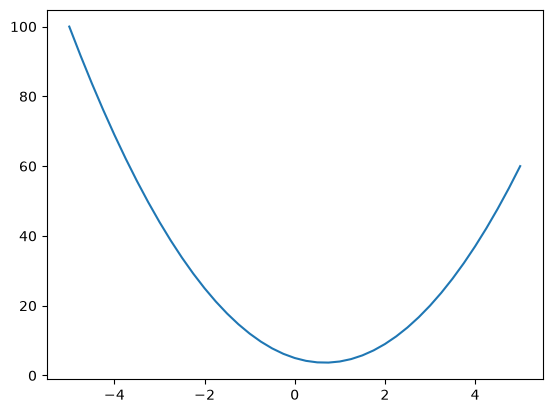

In [42]:
x = -5
inputs = []
outputs = []
while x <= 5:
    inputs.append(x)
    result = f(x)
    outputs.append(result)
    x += 0.25
    # x += 0.1 # print(inputs[-1]) # 4.999999999999997

plt.plot(inputs, outputs)

## 3. Nudge it
Pick `h`, nudge `x = 3.0`, measure rise over run. Then try x = -3.0, and find where it's ~0.

Read your answer as: "if I push x up a tiny bit, the output moves by about *slope* times that push."
- The **sign** tells you the direction: positive means the output goes up.
- The **size** tells you how sensitive the output is.
- At the flat point (slope ≈ 0) the output is at its lowest. Training is a search for exactly that kind of spot, with thousands of inputs instead of one.

In [ ]:
x = 3.0
h = 0.0001
f_x = f(x)
f_x_plus_h = f(x + h)
# rise means the change in output, run means the change in input
rise = f_x_plus_h - f_x
run = h # run is the push
# output change per one unit of push
slope = rise / run
print(f"The slope of f(x) at x = {x} is {slope}")
print(rise)

# Slope = output change per 1 unit of push (a rate).
# Rise  = output change for this particular push h. So rise ≈ slope * h.

# x = 3.0  → slope ≈ 14.003
#   sign: positive → pushing x right makes the output go UP
#   size: ~14 → push x by 1, output moves by ~14
#   with h = 0.001: output moves by ~14 * 0.001 = ~0.014 (the rise)

# x = -3.0 → slope ≈ -21.997
#   sign: negative → pushing x right makes the output go DOWN
#   size: ~22 → steeper here than at x = 3
#   with h = 0.001: output DEcreases by ~22 * 0.001 = ~0.022

# x = 0.5  → slope ≈ -0.997
#   still negative → still downhill going right, flat spot is further right
# ...
# x = 0.8 → slope ≈ 0.803
#  sign: positive → pushing x right makes the output go UP


The slope of f(x) at x = 0.8 is 0.8002999999989768
8.002999999989768e-05


### ⏸ Pick up here (paused 2026-11-21)

Sections 1-3 are built. Before starting section 4, finish these three. Answer each in a comment or a markdown cell.

**1. Find the flat spot. Not done yet.**
- x = 0.5 → slope ≈ -1.0 (still downhill)
- x = 0.8 → slope ≈ +0.8 (already uphill, so you went past it)
- The bottom is **between 0.5 and 0.8**. Try halfway and let the sign tell you which half to keep. Stop when the slope is about ±0.01.

**2. Why is the slope at x = 3 equal to 14.003, not 14?**
- Your first answer was "floating point". That isn't it. The tiny tail `...00000243` is float noise, but the `.003` is something else.
- Experiment: at x = 3, run h = 0.001, 0.0001, 0.00001. Write down the extra bit each time. Does it shrink in step with h?
- Then look at the plot near x = 3. Is the curve straight there, or bending? Why would a bigger push give a slightly bigger slope?

**3. Which way do you turn the knob?**
- Your first answer was "push x and check". That's re-measuring. Use only the slope you already have.
- At x = 3 the slope is +14. Pushing right makes the output go ___. To make it smaller, move x ___.
- At x = -3 the slope is -22. Which way?
- One rule: "move x in the direction ___ to the slope's sign." That rule is training.

Then explain section 3 back in your own words, and move on to section 4.


## 4. Break it
What happens to your slope as `h` gets tiny (1e-6, 1e-10, 1e-15, 1e-20)?

Predict first, then run. Smaller `h` *should* be more accurate. Is it? The reason has nothing to do with math and everything to do with how computers store numbers. This is also why real libraries don't compute slopes by nudging.

## 5. Three inputs
`d = a*b + c` with a=2.0, b=-3.0, c=10.0. Nudge each one separately. Predict the sign and size before running.

This is a net in miniature: several inputs, one output, and you want a slope for **each** input. Those per-input slopes are what the course calls **gradients**, and `a.grad` in the next lessons will hold exactly the number you measure here.

Notice the cost: each slope needed its own re-run of the expression. With 3 inputs that's fine. With a million weights it's hopeless, and that problem is why lesson 2 (the `Value` object) and backprop exist.